In [3]:
import numpy as np
import os
import json
import ast
import pandas as pd
from plotnine import (
    ggplot, aes, geom_line, geom_point, geom_errorbar, facet_wrap, geom_text,
    labs, theme_classic, theme, element_text, geom_vline, scale_y_continuous, geom_hline, scale_x_continuous, scale_color_manual, ggtitle, scale_shape_manual, position_dodge
)

## Load and preprocess data

In [4]:
stimColors = {'Rule': '#715cad', 'Exception': '#6fa8dcff'}

df = pd.read_csv('data/experiment1_raw.csv')
df = df[df['catch'] == False]

In [5]:
#  Count participants per curriculum 
n_per_curr = df.groupby('curriculum')['subjectId'].nunique().reset_index(name='n')
print(n_per_curr)
print("Total participants:", n_per_curr['n'].sum())

           curriculum   n
0  Complex\nTo Simple  72
1      No\nCurriculum  63
2  Simple\nTo Complex  72
Total participants: 207


## Simple-to-complex curricula facilitate learning  

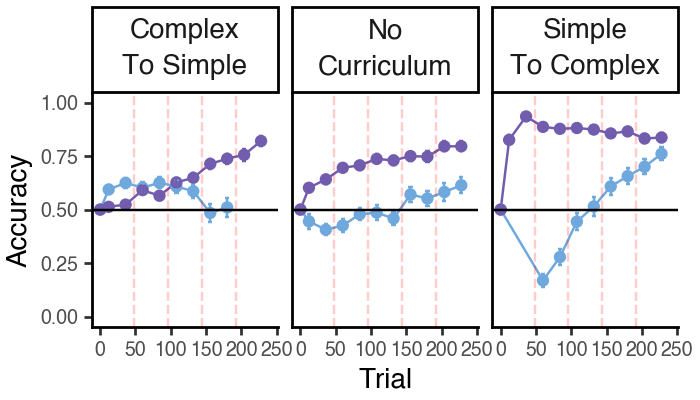

In [11]:
# Bin accuracy over trials of learning and plot by curriculumCondition (with n per condition)
bin_size = 24
df_learning = df[df['taskPart'] == 'learning'].copy()
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)
df_learning = df_learning[df_learning['timeout'] == False].copy()
df_learning['bin'] = ((df_learning['total_trial_num'] - 1) // bin_size) + 1
# Bin mid point for plotting (use trial number in x-axis)
df_learning['bin_mid'] = (df_learning['bin'] * bin_size - bin_size / 2).astype(float)

# Per-subject accuracy per bin
per_sub = (
    df_learning
    .groupby(['curriculum', 'subjectId','stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and standard error (SE)
summary = (
    per_sub
    .groupby(['curriculum', 'stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
# Create ymin/ymax columns for errorbars
summary['ymin'] = summary['mean_acc'] - summary['se']
summary['ymax'] = summary['mean_acc'] + summary['se']

# Prepend a starting point at (0, 0.5) representing chance accuracy for each group
start_points = (
    summary[['curriculum', 'stimType']]
    .drop_duplicates()
    .reset_index(drop=True)
)
start_points['bin'] = 0
start_points['bin_mid'] = 0.0
start_points['mean_acc'] = 0.5
start_points['se'] = np.nan
start_points['ymin'] = np.nan
start_points['ymax'] = np.nan
summary = pd.concat([start_points, summary], ignore_index=True).sort_values(
    ['curriculum', 'stimType', 'bin_mid']
)

# Compute vertical lines every 48 trials (in trial number space)
max_trial = int(df_learning['total_trial_num'].max())
vlines = list(range(48, max_trial, 48))
# Put vlines into a small DataFrame so plotnine treats them as continuous values
vline_df = pd.DataFrame({'x': vlines}) if len(vlines) > 0 else pd.DataFrame({'x': []})

# Build the plot
p = (
    ggplot(summary, aes(x='bin_mid', y='mean_acc', color='stimType', group='stimType'))
    + geom_line()
    + geom_point()
    + geom_errorbar(
        data=summary.dropna(subset=['ymin', 'ymax']),
        mapping=aes(ymin='ymin', ymax='ymax'),
        width=6
)    + facet_wrap('~curriculum')
    + (geom_vline(mapping=aes(xintercept='x'), data=vline_df, color='red', linetype='dashed', alpha=0.2) if not vline_df.empty else 0)
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + scale_x_continuous(limits=(0, max_trial))
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + labs(x='Trial', y='Accuracy', color='Stimulus Type')
    + theme(axis_text=element_text(size=7), text=element_text(size=10),figure_size=(3.5,2), panel_spacing_x=0.02, legend_position='none')
)
p

# p.save(
#     filename='analysis/figs/fig2C.svg',
#     format="svg",
#     verbose=False
# )

In [7]:
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)

df_learning[df_learning['curriculum'] == "No\nCurriculum"].to_csv('data/exp1_learning_control.csv', index=False)

## Effect of curricula at test

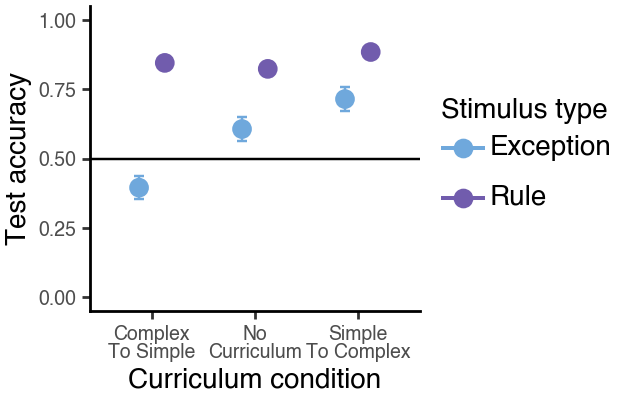

In [ ]:
# Plot test-phase accuracy by curriculum and stimType 

test_df = df[(df['taskPart'] == 'test') & (df['timeout'] == False)]

# Per-subject accuracy in the test phase per curriculum and stimType
per_sub_test = (
    test_df
    .groupby(['curriculum','subjectId', 'stimType'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and SE
summary_test = (
    per_sub_test
    .groupby(['curriculum', 'stimType'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
summary_test['ymin'] = summary_test['mean_acc'] - summary_test['se']
summary_test['ymax'] = summary_test['mean_acc'] + summary_test['se']

# Plot: curriculum on x-axis, accuracy on y-axis, stimType side-by-side
dodge = position_dodge(width=0.5)
p_test = (
    ggplot(summary_test, aes(x='curriculum', y='mean_acc', color='stimType'))
    + geom_point(position=dodge, size=3)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=0.2, position=dodge)
    + labs(x='Curriculum condition', y='Test accuracy', color='Stimulus type')
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    # make x tick labels larger and not tilted
    + theme(axis_text_x=element_text(rotation=0, ha='center', size=11))
    + theme(axis_text=element_text(size=7), text=element_text(size=10),figure_size=(3.1,2))
)

p_test

# p_test.save(
#     filename='analysis/figs/fig2D.svg',
#     format="svg",
#     verbose=False
# )

# test_df[test_df['curriculum'] == "No\nCurriculum"].to_csv('data/exp1_test_control.csv', index=False)
# test_df.to_csv('data/exp1_test.csv', index=False)